## Submission

Реализованы 
1. `MyGCNConv`
2. `MySAGEConv`

Оба класса лежат в `submission.py` - вывод тестов `tests_output.txt` (`root_dir` убрал специально)

---

In [1]:
import torch
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures

d:\Edu\ITMO\Courses\gnn-course-itmo-main\gnn_course-venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Edu\ITMO\Courses\gnn-course-itmo-main\gnn_course-venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


# Часть 2. Воспроизведение результата

**Baseline**: MLP той же архитектуры, не видящий рёбер.

In [2]:
from submission import MyGCNConv, MySAGEConv

class TwoLayerGNN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, conv_type='gcn'):
        super().__init__()
        if conv_type == 'gcn':
            self.conv1 = MyGCNConv(in_channels, hidden_channels)
            self.conv2 = MyGCNConv(hidden_channels, out_channels)
        else:
            self.conv1 = MySAGEConv(in_channels, hidden_channels)
            self.conv2 = MySAGEConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return x

In [3]:
class MLP(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.lin1 = torch.nn.Linear(in_channels, hidden_channels)
        self.lin2 = torch.nn.Linear(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.lin2(x)
        return x

In [ ]:
def load_dataset(name):
    dataset = Planetoid(root='/tmp/Planetoid', name=name, transform=NormalizeFeatures())
    data = dataset[0]
    data.num_classes = dataset.num_classes
    return data

def train_and_evaluate(model, data, train_mask=None, epochs=200,
                       lr=0.01, weight_decay=5e-4):
    if train_mask is None:
        train_mask = data.train_mask
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_acc = 0.0
    best_test_acc = 0.0
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[train_mask], data.y[train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            pred = model(data.x, data.edge_index).argmax(dim=1)
            val_acc  = (pred[data.val_mask]  == data.y[data.val_mask]).float().mean().item()
            test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
            if val_acc > best_val_acc:
                best_val_acc, best_test_acc = val_acc, test_acc
    return best_test_acc

In [16]:
import numpy as np

def run_experiments(dataset_name, seeds=[0,1,2,3,4]):
    data = load_dataset(dataset_name)
    results = {'GCN': [], 'SAGE': [], 'MLP': []}
    for seed in seeds:
        torch.manual_seed(seed)
        np.random.seed(seed)
        # GCN
        model = TwoLayerGNN(data.num_features, 16, data.num_classes, conv_type='gcn')
        acc = train_and_evaluate(model, data)
        results['GCN'].append(acc)
        # SAGE
        torch.manual_seed(seed)
        model = TwoLayerGNN(data.num_features, 16, data.num_classes, conv_type='sage')
        acc = train_and_evaluate(model, data)
        results['SAGE'].append(acc)
        # MLP
        torch.manual_seed(seed)
        model = MLP(data.num_features, 16, data.num_classes)
        acc = train_and_evaluate(model, data)
        results['MLP'].append(acc)
    return results

In [17]:
for name in ['Cora', 'CiteSeer']:
    print(f"\n{name}:")
    res = run_experiments(name)
    for model_name, accs in res.items():
        mean, std = np.mean(accs)*100, np.std(accs)*100
        print(f"{model_name}: {mean:.2f} $\pm$ {std:.2f}")


Cora:
GCN: 81.80 ± 0.57
SAGE: 80.14 ± 0.96
MLP: 56.96 ± 1.03

CiteSeer:


Processing...
Done!


GCN: 70.22 ± 1.02
SAGE: 70.28 ± 0.98
MLP: 57.80 ± 2.27


---

**Results (accuracy):**
1. Cora:
	- GCN: 81.80 ± 0.57
	- SAGE: 80.14 ± 0.96
	- MLP: 56.96 ± 1.03
2. CiteSeer:
	- GCN: 70.22 ± 1.02
	- SAGE: 70.28 ± 0.98
	- MLP: 57.80 ± 2.27

**Выводы:**
1. Результаты совпали с числами из статьи (Kipf & Welling (2017): Cora 81.5, CiteSeer 70.3);
2. Учёт графовой структуры даёт от 15% до 25% прироста (также улучшается стабильность - дисперсия метрик меньше).

---

# Часть 3. Что ломается при увеличении глубины

In [18]:
class DeepGNN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, num_layers):
        super().__init__()
        self.convs = torch.nn.ModuleList()
        self.convs.append(MyGCNConv(in_channels, hidden_channels))
        for _ in range(num_layers - 2):
            self.convs.append(MyGCNConv(hidden_channels, hidden_channels))
        self.convs.append(MyGCNConv(hidden_channels, out_channels))

    def forward(self, x, edge_index, return_hidden=False):
        hiddens = []
        for i, conv in enumerate(self.convs):
            x = conv(x, edge_index)
            if i < len(self.convs) - 1:
                x = F.relu(x)
                x = F.dropout(x, p=0.5, training=self.training)
            hiddens.append(x)
        if return_hidden:
            return x, hiddens
        return x

In [19]:
def mean_pairwise_cosine_similarity(h):
    h_norm = F.normalize(h, p=2, dim=1)
    sim_matrix = h_norm @ h_norm.T
    n = h.size(0)
    triu_indices = torch.triu_indices(n, n, offset=1)
    return sim_matrix[triu_indices[0], triu_indices[1]].mean().item()

In [20]:
data = load_dataset('Cora')
num_classes = data.num_classes
depths = [2, 4, 8, 16]
acc_results = {d: [] for d in depths}
sim_results = {d: [] for d in depths}

for d in depths:
    for seed in range(5):
        torch.manual_seed(seed)
        model = DeepGNN(data.num_features, 16, num_classes, num_layers=d)
        acc = train_and_evaluate(model, data)
        acc_results[d].append(acc)

        model.eval()
        with torch.no_grad():
            _, hiddens = model(data.x, data.edge_index, return_hidden=True)
            h = hiddens[-2]
            sim_results[d].append(mean_pairwise_cosine_similarity(h))

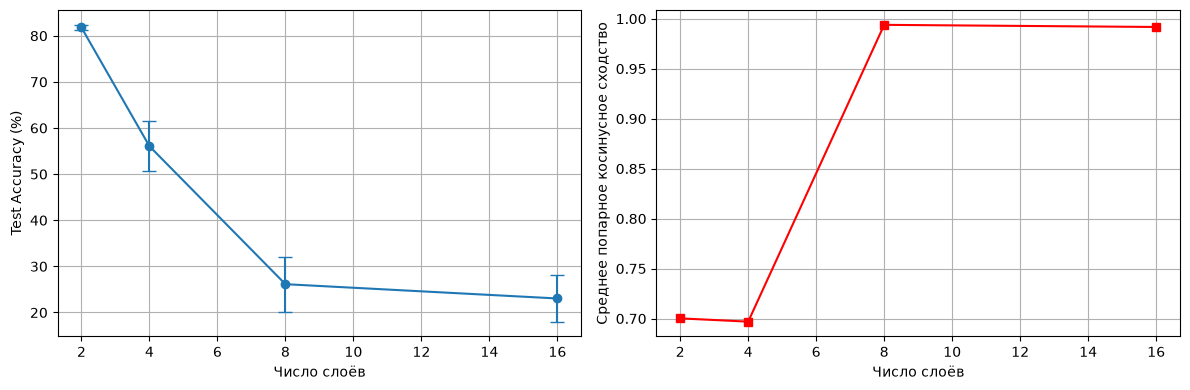

In [28]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
acc_means = [np.mean(acc_results[d])*100 for d in depths]
acc_stds = [np.std(acc_results[d])*100 for d in depths]
ax1.errorbar(depths, acc_means, yerr=acc_stds, marker='o', capsize=5)
ax1.set_xlabel('Число слоёв')
ax1.set_ylabel('Test Accuracy (%)')
ax1.grid(True)

sim_means = [np.mean(sim_results[d]) for d in depths]
ax2.plot(depths, sim_means, marker='s', color='red')
ax2.set_xlabel('Число слоёв')
ax2.set_ylabel('Среднее попарное косинусное сходство')
ax2.grid(True)
plt.tight_layout()
plt.show()

---

**Что произошло:**
- accuracy: уменьшается при увеличении количества слоёв,
- и если при 4-х слоях модель скорее всего недообучилась (попарное сходство даже уменьшилось по сравнению с 2-мя слоями) - отсюда низкое качество и большой разброс,
- то модели с 8-ю и 16-ю слоями не обучились: представления слиплись. 

**Объяснение:**
GCN-слой - это суть сглаживающий оператор на графе. При повторном применении представления вершин сходятся к доминирующему собственному вектору, который на связной компоненте почти константен, и классовая информация стирается.

---

Бонус A. Inductive-режим
---

In [22]:
from torch_geometric.utils import subgraph

data = load_dataset('Cora')

test_idx = data.test_mask.nonzero(as_tuple=False).view(-1)
new_node_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
new_node_mask[test_idx[:1000]] = True

train_nodes = ~new_node_mask

sub_edge_index, _ = subgraph(train_nodes, data.edge_index, relabel_nodes=True)
data_train_sub = data.clone()
data_train_sub.x          = data.x[train_nodes]
data_train_sub.y          = data.y[train_nodes]
data_train_sub.edge_index = sub_edge_index
data_train_sub.train_mask = data.train_mask[train_nodes]
data_train_sub.val_mask   = data.val_mask[train_nodes]

In [23]:
def train_inductive(model, data_sub, data_full, new_node_mask, epochs=200):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    best_val_acc = 0
    best_state = None
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(data_sub.x, data_sub.edge_index)
        loss = F.cross_entropy(out[data_sub.train_mask], data_sub.y[data_sub.train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_out = model(data_sub.x, data_sub.edge_index)
            val_pred = val_out.argmax(dim=1)
            val_acc = (val_pred[data_sub.val_mask] == data_sub.y[data_sub.val_mask]).float().mean().item()
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_state = model.state_dict()
    model.load_state_dict(best_state)

    model.eval()
    with torch.no_grad():
        out_full = model(data_full.x, data_full.edge_index)
        pred = out_full.argmax(dim=1)
        acc_new = (pred[new_node_mask] == data_full.y[new_node_mask]).float().mean().item()
    return acc_new

In [24]:
def train_transductive(model, data_full, new_node_mask, epochs=200):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    train_mask = data_full.train_mask
    val_mask = data_full.val_mask
    best_val_acc = 0
    best_state = None
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(data_full.x, data_full.edge_index)
        loss = F.cross_entropy(out[train_mask], data_full.y[train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_out = model(data_full.x, data_full.edge_index)
            val_pred = val_out.argmax(dim=1)
            val_acc = (val_pred[val_mask] == data_full.y[val_mask]).float().mean().item()
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_state = model.state_dict()
    model.load_state_dict(best_state)

    model.eval()
    with torch.no_grad():
        out_full = model(data_full.x, data_full.edge_index)
        pred = out_full.argmax(dim=1)
        acc_new = (pred[new_node_mask] == data_full.y[new_node_mask]).float().mean().item()
    return acc_new

In [25]:
inductive_accs = []
transductive_accs = []
for seed in range(5):
    torch.manual_seed(seed)
    model = TwoLayerGNN(data.num_features, 16, data.num_classes, conv_type='sage')
    inductive_accs.append(train_inductive(model, data_train_sub, data, new_node_mask))

    torch.manual_seed(seed)
    model = TwoLayerGNN(data.num_features, 16, data.num_classes, conv_type='sage')
    transductive_accs.append(train_transductive(model, data, new_node_mask))

print(f"Inductive:    {np.mean(inductive_accs)*100:.2f} ± {np.std(inductive_accs)*100:.2f}")
print(f"Transductive: {np.mean(transductive_accs)*100:.2f} ± {np.std(transductive_accs)*100:.2f}")

Inductive:    78.26 ± 1.11
Transductive: 80.38 ± 0.72


---

**Results:**
| Режим | Видела ли модель новые вершины при обучении? | Accuracy на новых вершинах |
|---|---|:--:|
| inductive | нет | 78.26 ± 1.11 |
| transductive | да, но без меток | 80.38 ± 0.72 |

---

Бонус B. Сколько разметки нужно графу
---

In [26]:
fractions = [0.01, 0.05, 0.20, 0.60]
gcn_accs = []
mlp_accs = []

for frac in fractions:
    gcn_frac_accs = []
    mlp_frac_accs = []
    for seed in range(5):
        torch.manual_seed(seed)
        np.random.seed(seed)

        n_train = int(data.num_nodes * frac)
        train_idx = torch.randperm(data.num_nodes)[:n_train]
        train_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
        train_mask[train_idx] = True

        # GCN
        torch.manual_seed(seed)
        model_gcn = TwoLayerGNN(data.num_features, 16, data.num_classes, conv_type='gcn')
        acc_gcn = train_and_evaluate(model_gcn, data, train_mask=train_mask)
        gcn_frac_accs.append(acc_gcn)

        # MLP
        torch.manual_seed(seed)
        model_mlp = MLP(data.num_features, 16, data.num_classes)
        acc_mlp = train_and_evaluate(model_mlp, data, train_mask=train_mask)
        mlp_frac_accs.append(acc_mlp)

    gcn_accs.append(np.mean(gcn_frac_accs)*100)
    mlp_accs.append(np.mean(mlp_frac_accs)*100)

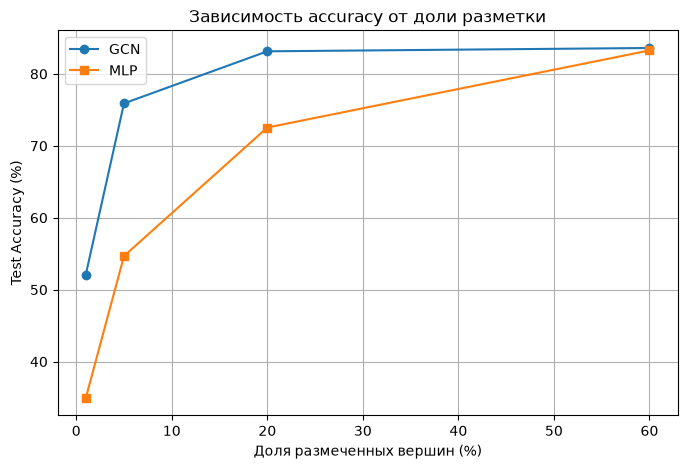

In [27]:
plt.figure(figsize=(8, 5))
plt.plot([f*100 for f in fractions], gcn_accs, marker='o', label='GCN')
plt.plot([f*100 for f in fractions], mlp_accs, marker='s', label='MLP')
plt.xlabel('Доля размеченных вершин (%)')
plt.ylabel('Test Accuracy (%)')
plt.title('Зависимость accuracy от доли разметки')
plt.legend()
plt.grid(True)
plt.show()

**Results:**
- при 1% разметки GCN существенно превосходит MLP (+20%);
- при 5–20% разрыв сокращается (10-20%);
- при 60% разрыв минимален.

**Вывод:** граф максимально полезен при низкой доле разметке - граф работает как регулятор. При достаточном количестве разметки (`>50%`) MLP уже способен выучить паттерны из одних признаков, и структурная информация перестаёт быть критичной.